In [1]:
# Stage 1: Import Libraries

import pandas as pd
import numpy as np

# Load the diabetes dataset

df = pd.read_csv('/content/diabetes.csv')

# Display dataset information

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
# Stage 2: Dataset Inspection

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display statistical description
print("\nStatistical Description:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display first five records
print("\nFirst Five Records:")
display(df.head())

Dataset Shape: (768, 9)

Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Description:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

First Five Records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:

# Stage 3: Handle Hidden Missing Values

# Identify columns containing hidden missing values
medical_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Replace zero values with NaN
df[medical_columns] = df[medical_columns].replace(0, np.nan)

# Display missing values after replacement
print("Missing Values After Replacing Zeros:")
print(df.isnull().sum())

# Display total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nHidden missing values handled successfully!")


Missing Values After Replacing Zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Total Missing Values:
652

Hidden missing values handled successfully!


In [4]:

# Stage 4: Separate Features and Target

# Separate input features
X = df.drop("Outcome", axis=1)

# Separate target variable
y = df["Outcome"]

# Display feature information
print("Features (X):")
print(X.head())

# Display target information
print("\nTarget (y):")
print(y.head())

# Display shapes
print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeatures and Target separated successfully!")


Features (X):
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0      NaN  33.6   
1            1     85.0           66.0           29.0      NaN  26.6   
2            8    183.0           64.0            NaN      NaN  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  

Target (y):
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64

Features Shape: (768, 8)
Target Shape: (768,)

Features and Target separated successfully!


In [5]:

# Stage 5: Train-Test Split with Stratification

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display training and testing shapes
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Check target distribution
print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

print("\nTrain-Test Split Completed Successfully!")


Training Features Shape: (614, 8)
Testing Features Shape: (154, 8)

Training Target Shape: (614,)
Testing Target Shape: (154,)

Training Target Distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Testing Target Distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64

Train-Test Split Completed Successfully!


In [6]:

# Stage 6: Feature Scaling using StandardScaler

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Step 1: Handle missing values using median
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Step 2: Apply StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Display scaled data
print("Scaled Training Data:")
print(X_train_scaled[:5])

print("\nScaled Testing Data:")
print(X_test_scaled[:5])

# Check mean and standard deviation
print("\nTraining Data Mean:", X_train_scaled.mean().round(2))
print("Training Data Standard Deviation:", X_train_scaled.std().round(2))

print("\nFeature Scaling Completed Successfully!")


Scaled Training Data:
[[-0.85135507 -1.05642747 -0.82674004 -1.91818693 -1.20336073 -0.76969431
   0.31079384 -0.79216928]
 [ 0.35657564  0.14439907  0.47777235 -0.22987447 -1.47019479 -0.41771394
  -0.11643851  0.56103382]
 [-0.5493724  -0.55608308 -1.15286813  1.23332967 -0.55533518  0.35957603
  -0.76486207 -0.70759409]
 [-0.85135507  0.81152492 -1.31593218 -0.00476614 -0.16143729 -0.40304809
   0.26231357 -0.36929331]
 [-1.15333775 -0.88964601 -0.66367599  1.12077551 -0.41556496  1.78216334
  -0.33762972 -0.96131967]]

Scaled Testing Data:
[[ 0.96054099  1.24515673 -0.66367599 -0.00476614 -0.16143729 -0.74036261
  -0.55579092  0.56103382]
 [ 1.86648903 -1.79026591  2.76066903 -0.68009112 -1.12712243  0.44757112
  -0.58306107  1.15306018]
 [-0.5493724   0.01097389  0.3147083  -0.22987447  0.79154147  0.50623452
   0.01688223 -0.6230189 ]
 [ 0.96054099 -0.25587645 -0.66367599 -0.00476614 -0.16143729 -0.74036261
   0.77135637  0.05358266]
 [-0.5493724  -1.59012816 -0.01141979 -0.00476

In [7]:

# Stage 7: K-Nearest Neighbors (KNN)

from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

# Predict test data
knn_predictions = knn_model.predict(X_test_scaled)

# Display predictions
print("KNN Predictions:")
print(knn_predictions[:20])

# Display actual values
print("\nActual Outcomes:")
print(y_test.iloc[:20].values)

print("\nKNN Model Trained Successfully!")


KNN Predictions:
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0]

Actual Outcomes:
[0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0]

KNN Model Trained Successfully!


In [8]:

# Stage 8: Logistic Regression

from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Predict test data
lr_predictions = lr_model.predict(X_test_scaled)

# Display predictions
print("Logistic Regression Predictions:")
print(lr_predictions[:20])

# Display actual values
print("\nActual Outcomes:")
print(y_test.iloc[:20].values)

print("\nLogistic Regression Model Trained Successfully!")


Logistic Regression Predictions:
[1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0]

Actual Outcomes:
[0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0]

Logistic Regression Model Trained Successfully!


In [9]:

# Stage 9: Decision Tree

from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the model
dt_model.fit(X_train_scaled, y_train)

# Predict test data
dt_predictions = dt_model.predict(X_test_scaled)

# Display predictions
print("Decision Tree Predictions:")
print(dt_predictions[:20])

# Display actual values
print("\nActual Outcomes:")
print(y_test.iloc[:20].values)

print("\nDecision Tree Model Trained Successfully!")


Decision Tree Predictions:
[1 0 0 1 0 0 0 1 0 1 1 1 0 0 0 1 1 0 1 0]

Actual Outcomes:
[0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0]

Decision Tree Model Trained Successfully!


In [10]:

# Stage 10: Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Store all models and predictions
models = {
    "KNN": knn_predictions,
    "Logistic Regression": lr_predictions,
    "Decision Tree": dt_predictions
}

# Evaluate each model
for name, predictions in models.items():

    print("\n==========", name, "==========")

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))

    # Display confusion matrix
    cm = confusion_matrix(y_test, predictions)

    print("\nConfusion Matrix:")
    print(cm)

print("\nAll Models Evaluated Successfully!")



========== KNN ==========
Accuracy: 0.7532
Precision: 0.66
Recall: 0.6111
F1-Score: 0.6346

Confusion Matrix:
[[83 17]
 [21 33]]

========== Logistic Regression ==========
Accuracy: 0.7078
Precision: 0.6
Recall: 0.5
F1-Score: 0.5455

Confusion Matrix:
[[82 18]
 [27 27]]

========== Decision Tree ==========
Accuracy: 0.7597
Precision: 0.6393
Recall: 0.7222
F1-Score: 0.6783

Confusion Matrix:
[[78 22]
 [15 39]]

All Models Evaluated Successfully!


In [11]:

# Stage 11: Threshold Tuning

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Split training data into training and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    random_state=42,
    stratify=y_train
)

# Store the three algorithms
algorithms = {
    "KNN": knn_model,
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model
}

tuned_thresholds = {}

# Tune threshold for each model
for name, algorithm in algorithms.items():

    # Create preprocessing and model pipeline
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", clone(algorithm))
    ])

    # Train using training portion
    pipeline.fit(X_fit, y_fit)

    # Calculate validation probabilities
    probabilities = pipeline.predict_proba(X_val)[:, 1]

    # Set threshold for approximately top 30% risk
    threshold = np.percentile(probabilities, 70)

    tuned_thresholds[name] = threshold

    # Calculate selected patients
    predictions = (probabilities >= threshold).astype(int)

    selected_percentage = predictions.mean() * 100

    print("\nModel:", name)
    print("Tuned Threshold:", round(threshold, 4))
    print("Patients selected:", round(selected_percentage, 2), "%")

print("\nThreshold Tuning Completed Successfully!")



Model: KNN
Tuned Threshold: 0.6
Patients selected: 31.17 %

Model: Logistic Regression
Tuned Threshold: 0.4547
Patients selected: 29.87 %

Model: Decision Tree
Tuned Threshold: 0.4898
Patients selected: 42.21 %

Threshold Tuning Completed Successfully!


In [12]:

# Stage 12: Select Top 30% High-Risk Patients

for name, algorithm in algorithms.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", clone(algorithm))
    ])

    pipeline.fit(X_fit, y_fit)

    probabilities = pipeline.predict_proba(X_val)[:, 1]

    # Calculate number of patients to select
    number_to_select = int(np.ceil(len(probabilities) * 0.30))

    # Select patients with the highest risk
    selected_indices = np.argsort(probabilities)[-number_to_select:]

    predictions = np.zeros(len(probabilities), dtype=int)
    predictions[selected_indices] = 1

    print("\nModel:", name)
    print("Total validation patients:", len(probabilities))
    print("High-risk patients selected:", predictions.sum())
    print("Selection percentage:",
          round(predictions.mean() * 100, 2), "%")

print("\nTop 30% Patient Selection Completed!")



Model: KNN
Total validation patients: 154
High-risk patients selected: 47
Selection percentage: 30.52 %

Model: Logistic Regression
Total validation patients: 154
High-risk patients selected: 47
Selection percentage: 30.52 %

Model: Decision Tree
Total validation patients: 154
High-risk patients selected: 47
Selection percentage: 30.52 %

Top 30% Patient Selection Completed!


In [13]:

# Stage 13: Evaluate Models Based on Top 30% Selection

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

results = {}

for name, algorithm in algorithms.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", clone(algorithm))
    ])

    pipeline.fit(X_fit, y_fit)

    probabilities = pipeline.predict_proba(X_val)[:, 1]

    # Select the top 30% highest-risk patients
    number_to_select = int(np.ceil(len(probabilities) * 0.30))
    selected_indices = np.argsort(probabilities)[-number_to_select:]

    predictions = np.zeros(len(probabilities), dtype=int)
    predictions[selected_indices] = 1

    # Evaluate model performance
    accuracy = accuracy_score(y_val, predictions)
    precision = precision_score(y_val, predictions, zero_division=0)
    recall = recall_score(y_val, predictions, zero_division=0)
    f1 = f1_score(y_val, predictions, zero_division=0)
    cm = confusion_matrix(y_val, predictions)

    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

    print("\n==========", name, "==========")
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))
    print("Confusion Matrix:")
    print(cm)

# Display comparison table
results_df = pd.DataFrame(results).T

print("\nFINAL MODEL COMPARISON:")
display(results_df)

print("\nModel Comparison Completed Successfully!")



========== KNN ==========
Accuracy: 0.7987
Precision: 0.7447
Recall: 0.6481
F1-Score: 0.6931
Confusion Matrix:
[[88 12]
 [19 35]]

========== Logistic Regression ==========
Accuracy: 0.7857
Precision: 0.7234
Recall: 0.6296
F1-Score: 0.6733
Confusion Matrix:
[[87 13]
 [20 34]]

========== Decision Tree ==========
Accuracy: 0.7727
Precision: 0.7021
Recall: 0.6111
F1-Score: 0.6535
Confusion Matrix:
[[86 14]
 [21 33]]

FINAL MODEL COMPARISON:


,Accuracy,Precision,Recall,F1-Score
KNN,0.798701,0.744681,0.648148,0.693069
Logistic Regression,0.785714,0.723404,0.629630,0.673267
Decision Tree,0.772727,0.702128,0.611111,0.653465



Model Comparison Completed Successfully!


In [14]:

# Stage 14: Select the Best Performing Model

# Find the model with the highest F1-score
best_model_name = results_df["F1-Score"].idxmax()

best_accuracy = results_df.loc[best_model_name, "Accuracy"]
best_precision = results_df.loc[best_model_name, "Precision"]
best_recall = results_df.loc[best_model_name, "Recall"]
best_f1 = results_df.loc[best_model_name, "F1-Score"]

print("========== WINNING MODEL ==========")

print("Best Model:", best_model_name)
print("Accuracy:", round(best_accuracy * 100, 2), "%")
print("Precision:", round(best_precision * 100, 2), "%")
print("Recall:", round(best_recall * 100, 2), "%")
print("F1-Score:", round(best_f1 * 100, 2), "%")

print("\nWinning Model Selected Successfully!")


========== WINNING MODEL ==========
Best Model: KNN
Accuracy: 79.87 %
Precision: 74.47 %
Recall: 64.81 %
F1-Score: 69.31 %

Winning Model Selected Successfully!


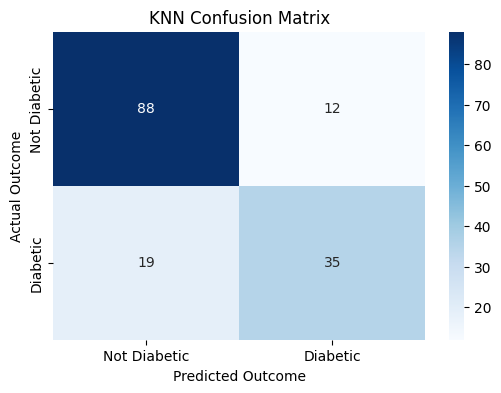

Confusion Matrix Visualization Completed!


In [15]:

# Stage 15: Confusion Matrix Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Get KNN predictions from the final comparison
best_predictions = np.zeros(len(y_val), dtype=int)

best_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", clone(algorithms["KNN"]))
])

best_pipeline.fit(X_fit, y_fit)

best_probabilities = best_pipeline.predict_proba(X_val)[:, 1]

number_to_select = int(np.ceil(len(best_probabilities) * 0.30))
selected_indices = np.argsort(best_probabilities)[-number_to_select:]

best_predictions[selected_indices] = 1

# Create confusion matrix
cm = confusion_matrix(y_val, best_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Diabetic", "Diabetic"],
    yticklabels=["Not Diabetic", "Diabetic"]
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.show()

print("Confusion Matrix Visualization Completed!")


In [16]:

# Stage 16: Save the Trained KNN Model

import joblib

# Save the trained model
joblib.dump(best_pipeline, "/content/diabetes_knn_model.pkl")

print("KNN Model Saved Successfully!")

# Check saved file
import os

print("File Exists:", os.path.exists("/content/diabetes_knn_model.pkl"))


KNN Model Saved Successfully!
File Exists: True


In [17]:

# Stage 17: Load and Test the Saved Model

import joblib

# Load the saved KNN model
loaded_model = joblib.load("/content/diabetes_knn_model.pkl")

# Make predictions using test data
test_predictions = loaded_model.predict(X_val)

# Display actual and predicted results
print("Actual Outcomes:")
print(y_val.head(10).values)

print("\nPredicted Outcomes:")
print(test_predictions[:10])

print("\nSaved Model Tested Successfully!")


Actual Outcomes:
[0 0 0 1 1 1 0 1 1 1]

Predicted Outcomes:
[0 1 0 0 0 0 1 0 1 1]

Saved Model Tested Successfully!


In [18]:

# Stage 18: Export Prediction Results

from google.colab import files
import pandas as pd

# Create prediction results table
prediction_results = pd.DataFrame({
    "Actual_Outcome": y_val.values,
    "Predicted_Outcome": test_predictions
})

# Save results as CSV
prediction_results.to_csv(
    "/content/Diabetes_Prediction_Results.csv",
    index=False
)

print("Prediction Results Exported Successfully!")

# Download the results
files.download("/content/Diabetes_Prediction_Results.csv")


Prediction Results Exported Successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>